****Face Emotion Recognition using FER-2013****

**Dataset: FER-2013 on Kaggle**

**1. Project Overview**

This project classifies a detected face into one of seven emotion categories: surprise, sad, neutral, happy, fear, disgust, or angry.

The notebook documents the dataset preparation and the MobileNetV2-based model used for training, followed by loading the saved model for inference.

**Important:** The model has already been trained. Do not run the model-training cell unless you intentionally want to train again. Training previously took a very long time. The notebook is arranged for documentation and reuse, not as a requirement to retrain the model.

In [1]:
#2.Import the libraries needed for prediction
import os
import random
import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow version:", tf.__version__)
print("OpenCV version:", cv2.__version__)

TensorFlow version: 2.21.0
OpenCV version: 4.11.0


In [3]:
# 3. Dataset Location and Emotion Labels
# Extract the Kaggle dataset into the project folder so the training images are available under Face Emotion Data/train/.
# Keep the class order below unchanged. The integer label for each emotion is based on its position in this list, and the model output uses this same order.
Datadirectory = os.path.join("Face Emotion Data", "train")

Classes = [
    "surprise",
    "sad",
    "neutral",
    "happy",
    "fear",
    "disgust",
    "angry"
]

if not os.path.isdir(Datadirectory):
    raise FileNotFoundError(
        "Dataset folder not found: " + Datadirectory
    )

print("Dataset folder:", Datadirectory)
print("Emotion classes and label indexes:")
for index, emotion in enumerate(Classes):
    print(index, emotion)

Dataset folder: Face Emotion Data\train
Emotion classes and label indexes:
0 surprise
1 sad
2 neutral
3 happy
4 fear
5 disgust
6 angry


In [4]:
# 4. Explore the Dataset
for category in Classes:
    path = os.path.join(Datadirectory, category)
    if os.path.isdir(path):
        image_files = os.listdir(path)
        print(category, ":", len(image_files), "images")
    else:
        print("Missing class folder:", category)

surprise : 3171 images
sad : 4830 images
neutral : 4965 images
happy : 7215 images
fear : 4097 images
disgust : 436 images
angry : 3995 images


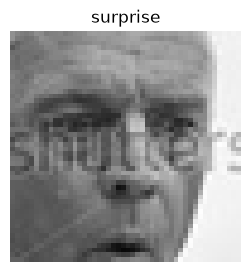

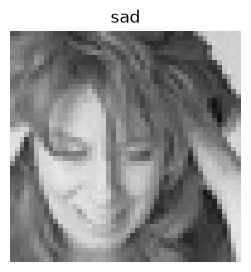

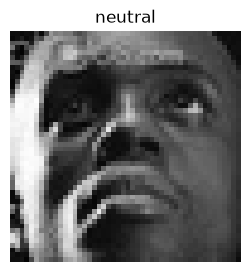

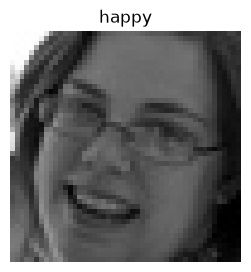

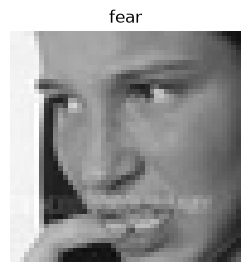

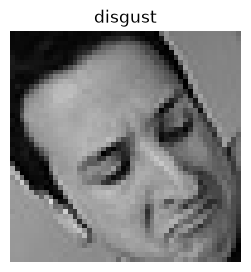

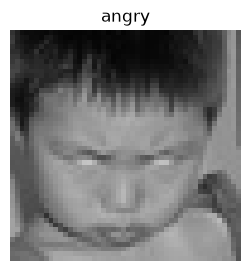

In [5]:
# Display one example image from each emotion folder.
for category in Classes:
    path = os.path.join(Datadirectory, category)
    if not os.path.isdir(path):
        continue

    image_files = os.listdir(path)
    shown = False

    for image_name in image_files:
        image_path = os.path.join(path, image_name)
        image = cv2.imread(image_path)

        if image is not None:
            image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
            plt.figure(figsize=(3, 3))
            plt.imshow(image_rgb)
            plt.title(category)
            plt.axis("off")
            plt.show()
            shown = True
            break

    if not shown:
        print("No readable image found for:", category)

**5. Image Preprocessing**

The original training code resizes each image to 224 × 224 pixels and keeps three color channels. It stores the pixel values in the 0–255 range. The inference scripts should use the same pixel-value range.

In [6]:
# 5. Image Preprocessing
img_size = 224
training_Data = []

def create_training_Data():
    training_Data.clear()

    for category in Classes:
        path = os.path.join(Datadirectory, category)
        class_num = Classes.index(category)

        for img_name in os.listdir(path):
            img_path = os.path.join(path, img_name)

            try:
                img_array = cv2.imread(img_path)
                if img_array is None:
                    continue

                new_array = cv2.resize(
                    img_array, (img_size, img_size)
                )
                training_Data.append([new_array, class_num])
            except (cv2.error, OSError, ValueError):
                # Skip unreadable or invalid images.
                continue

create_training_Data()
print("Total readable images:", len(training_Data))

Total readable images: 28709


In [7]:
# Shuffle the images so the emotion classes are mixed.
random.shuffle(training_Data)

X = np.array(
    [features for features, label in training_Data],
    dtype=np.uint8
)

y = np.array(
    [label for features, label in training_Data],
    dtype=np.int32
)

print("X shape:", X.shape)
print("X data type:", X.dtype)
print("y shape:", y.shape)
print("Label values:", np.unique(y))

X shape: (28709, 224, 224, 3)
X data type: uint8
y shape: (28709,)
Label values: [0 1 2 3 4 5 6]


**6. Build the MobileNetV2-Based Model**

The original notebook uses MobileNetV2 as the base model and adds dense layers for seven-class emotion classification. This section reconstructs the architecture; it does not train the model.

In [16]:
base_model = tf.keras.applications.MobileNetV2()

base_input = base_model.input
base_output = base_model.layers[-2].output

final_output = layers.Dense(128)(base_output)
final_output = layers.Activation("relu")(final_output)
final_output = layers.Dense(64)(final_output)
final_output = layers.Activation("relu")(final_output)
final_output = layers.Dense(7, activation="softmax")(final_output)

model = keras.Model(inputs=base_input, outputs=final_output)

model.compile(
    loss="sparse_categorical_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,430,663 (9.27 MB)

 Trainable params: 2,396,551 (9.14 MB)

 Non-trainable params: 34,112 (133.25 KB)

**7. Model Training (Reference Only — Do Not Run Again)**

The original project trained the model for 25 epochs and saved it as Final_model_95p07.h5. The filename does not by itself verify the model's test accuracy.

Do not run the next cell for normal project use. It is included to document the training command. Running it will start training again and may take a long time.

In [ ]:
# new_model.fit(X,Y, epochs=25)  ##Train the model

Epoch 1/25
898/898 ━━━━━━━━━━━━━━━━━━━━ 2283s 2s/step - accuracy: 0.5304 - loss: 1.2510
Epoch 2/25
898/898 ━━━━━━━━━━━━━━━━━━━━ 33445s 37s/step - accuracy: 0.6010 - loss: 1.0746
Epoch 3/25
898/898 ━━━━━━━━━━━━━━━━━━━━ 1886s 2s/step - accuracy: 0.6268 - loss: 1.0014
Epoch 4/25
898/898 ━━━━━━━━━━━━━━━━━━━━ 1961s 2s/step - accuracy: 0.6479 - loss: 0.9466
Epoch 5/25
898/898 ━━━━━━━━━━━━━━━━━━━━ 3107s 3s/step - accuracy: 0.6685 - loss: 0.8924
Epoch 6/25
898/898 ━━━━━━━━━━━━━━━━━━━━ 3247s 4s/step - accuracy: 0.6884 - loss: 0.8410
Epoch 7/25
898/898 ━━━━━━━━━━━━━━━━━━━━ 3233s 4s/step - accuracy: 0.7050 - loss: 0.7936
Epoch 8/25
898/898 ━━━━━━━━━━━━━━━━━━━━ 3284s 4s/step - accuracy: 0.7250 - loss: 0.7438
Epoch 9/25
898/898 ━━━━━━━━━━━━━━━━━━━━ 3376s 4s/step - accuracy: 0.7470 - loss: 0.6914
Epoch 10/25
898/898 ━━━━━━━━━━━━━━━━━━━━ 2901s 3s/step - accuracy: 0.7662 - loss: 0.6411
Epoch 11/25
898/898 ━━━━━━━━━━━━━━━━━━━━ 3417s 4s/step - accuracy: 0.7877 - loss: 0.5825
Epoch 12/25
898/898 ━━━━━━━━

In [17]:
# 8. Save the trained model
# model.save("models/Final_model_95p07.h5")

In [16]:
# 9. Load the trained model

import os
import tensorflow as tf

model_path = os.path.join(
    "models",
    "Final_model_95p07.h5"
)

new_model = tf.keras.models.load_model(model_path)

print("Model loaded successfully!")

Model loaded successfully!


In [18]:
# 10. Define the emotion labels

Classes = [
    "surprise",
    "sad",
    "neutral",
    "happy",
    "fear",
    "disgust",
    "angry"
]

print("Emotion classes:", Classes)

Emotion classes: ['surprise', 'sad', 'neutral', 'happy', 'fear', 'disgust', 'angry']


In [ ]:
image_path = input("Enter the image path: ")

In [20]:
# 11. Predict emotion from a single image

import cv2
import numpy as np

image = cv2.imread(image_path)

if image is None:
    print("Image not found. Check the file path.")

else:
    face_cascade = cv2.CascadeClassifier(
        cv2.data.haarcascades +
        "haarcascade_frontalface_default.xml"
    )

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    faces = face_cascade.detectMultiScale(
        gray,
        scaleFactor=1.1,
        minNeighbors=4
    )

    if len(faces) == 0:
        print("No face detected.")

    else:
        x, y, w, h = faces[0]

        face = image[y:y+h, x:x+w]
        face = cv2.resize(face, (224, 224))
        face = np.expand_dims(face, axis=0)
        face = face.astype("float32")

        prediction = new_model.predict(face, verbose=0)
        index = int(np.argmax(prediction[0]))

        print("Predicted emotion:", Classes[index])
        print("\nEmotion scores:")

        for i, emotion in enumerate(Classes):
            score = float(prediction[0][i]) * 100
            print(emotion, ":", round(score, 2), "%")

        cv2.rectangle(
            image, (x, y), (x+w, y+h), (0, 255, 0), 2
        )

        cv2.putText(
            image,
            Classes[index].capitalize(),
            (x, max(y-10, 25)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.8,
            (0, 255, 0),
            2
        )

        cv2.imshow("Emotion Prediction", image)
        cv2.waitKey(0)
        cv2.destroyAllWindows()

Predicted emotion: happy

Emotion scores:
surprise : 0.0 %
sad : 0.0 %
neutral : 0.0 %
happy : 100.0 %
fear : 0.0 %
disgust : 0.0 %
angry : 0.0 %


## 12. Project Limitations

- Predictions may not always be correct.
- Lighting, camera quality, and face position can affect predictions.
- Some expressions, especially fear and disgust, may be difficult to distinguish.
- The model predicts facial-expression categories and cannot determine a person's actual emotional state with certainty.

## 13. Conclusion

This project uses the FER-2013 dataset from Kaggle to build a facial emotion recognition system using deep learning.

The trained model predicts seven facial-expression categories: surprise, sad, neutral, happy, fear, disgust, and angry.

The project supports emotion prediction from a single image and real-time webcam recognition through a separate Python application.